In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://data.wprdc.org/datastore/dump/29462525-62a6-45bf-9b5e-ad2e1c06348d"
df_311 = pd.read_csv(url)

df_311.columns = df_311.columns.str.lower()

df_311 = df_311.dropna(subset=['neighborhood'])

print(df_311['neighborhood'].value_counts().head())

neighborhood
Brookline              32245
Carrick                31017
South Side Flats       29758
South Side Slopes      29508
Squirrel Hill South    29226
Name: count, dtype: int64


Top 10 Neighborhoods with Fewest 311 Complaints:
            neighborhood  request_count
52  Mount Oliver Borough             98
4      Arlington Heights            167
35            Glen Hazel            477
58     Northview Heights            836
67             Ridgemont            909
26         East Carnegie            950
78             St. Clair           1032
20        Chartiers City           1125
31             Fairywood           1172
71           South Shore           1343


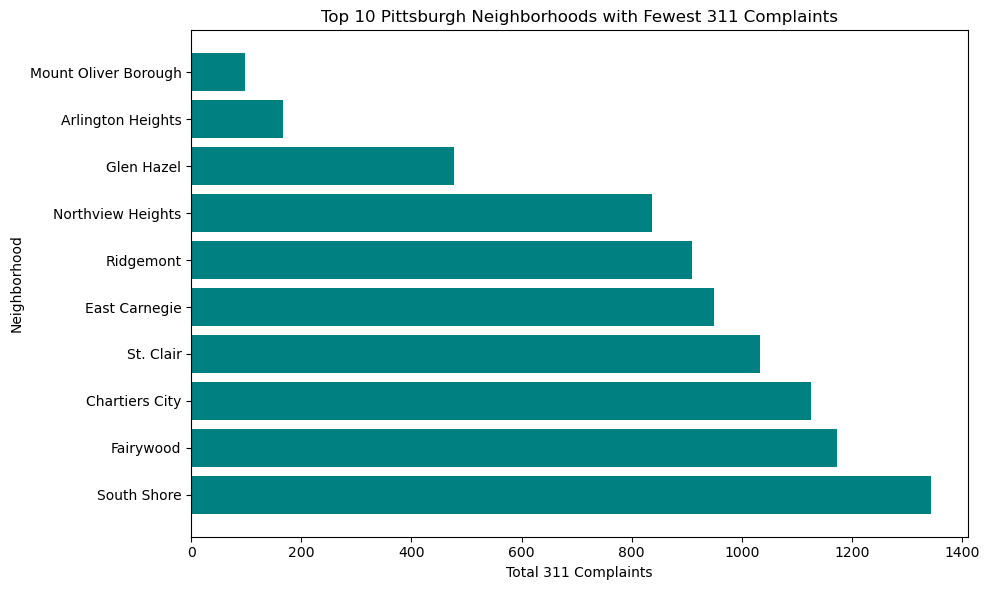

In [3]:
import matplotlib.pyplot as plt

neighborhood_311 = df_311.groupby('neighborhood').size().reset_index(name='request_count')

neighborhood_311_sorted = neighborhood_311.sort_values(by='request_count', ascending=True)

print("Top 10 Neighborhoods with Fewest 311 Complaints:")
print(neighborhood_311_sorted.head(10))

min_val = neighborhood_311['request_count'].min()
max_val = neighborhood_311['request_count'].max()
neighborhood_311['score_311'] = 100 * (1 - (neighborhood_311['request_count'] - min_val) / (max_val - min_val))

neighborhood_scores = neighborhood_311[['neighborhood', 'request_count', 'score_311']].sort_values(by='score_311', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(neighborhood_311_sorted['neighborhood'].head(10), 
         neighborhood_311_sorted['request_count'].head(10), 
         color='teal')
plt.xlabel('Total 311 Complaints')
plt.ylabel('Neighborhood')
plt.title('Top 10 Pittsburgh Neighborhoods with Fewest 311 Complaints')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Analysis of 311 Service Requests

Based on raw 311 complaint counts, **Mount Oliver Borough**, **Arlington Heights**, and **Glen Hazel** rank as the top 3 "best" neighborhoods in Pittsburgh due to having the lowest volume of reported city service complaints.

#### Key Data Considerations & Limitations:
1. **Administrative Boundary Artifacts**: *Mount Oliver Borough* appears with only 98 complaints because it is an independent borough completely surrounded by Pittsburgh, meaning most municipal services are handled outside the City of Pittsburgh 311 system rather than reflecting a lack of issues.
2. **Population & Geographic Density**: Smaller residential areas such as *Arlington Heights* and *Glen Hazel* naturally produce fewer overall 311 calls than large, densely populated neighborhoods like *Brookline* or *Squirrel Hill South*.
3. **Land Use Variation**: *South Shore* ranks in the top 10 largely because it is primarily commercial and industrial along the riverfront rather than residential, resulting in fewer residential service requests.

In [5]:

submetric_311 = neighborhood_311[['neighborhood', 'request_count', 'score_311']].copy()

submetric_311 = submetric_311.sort_values(by='score_311', ascending=False)

submetric_311.to_csv('submetric_311_requests.csv', index=False)

print("Top 5 scores:")
print(submetric_311.head())

Top 5 scores:
            neighborhood  request_count   score_311
52  Mount Oliver Borough             98  100.000000
4      Arlington Heights            167   99.785361
35            Glen Hazel            477   98.821041
58     Northview Heights            836   97.704296
67             Ridgemont            909   97.477214


## Conclusion & Personal Reflection

According to the raw 311 service request dataset, **Mount Oliver Borough** (98 requests) and **Arlington Heights** (167 requests) officially ranked as the best neighborhoods in Pittsburgh due to having the lowest volume of reported municipal complaints. 

Analyzing this metric reveals how raw data reflects reality:
* **Administrative Edge Cases**: Mount Oliver Borough is an independent enclave surrounded by Pittsburgh, meaning its municipal service requests are largely handled outside the city's 311 system. 
* **Population & Density Bias**: Neighborhoods with smaller populations naturally generate far fewer complaints than dense residential or commercial hubs like Brookline or South Side Flats. 
* **Civic Engagement vs. Nuisance**: A high 311 volume doesn't mean a neighborhood is undesirable. It can signifiy an engaged community that actively reports issues to improve their surroundings. However, fewer complaints can sometimes reflect lower resident reporting rather than perfect infrastructure.

### Comparison with Personal Favorite
My personal favorite neighborhood in Pittsburgh is **Central Oakland**. 

In contrast to quiet, low-density neighborhoods like Arlington Heights, Central Oakland ranks much lower on this specific submetric because it generates a significantly higher volume of 311 requests. As the heart of Pitt's campus, Central Oakland experiences intense population density, constant foot traffic, frequent student turnover, and ongoing municipal issues related to move-in trash, parking, street maintenance, and noise. 

Despite these data points, Central Oakland remains my favorite neighborhood due to its energy and convenience. It offers immediate proximity to classes, vibrant dining options along Forbes and Fifth Avenues, landmarks like the Cathedral of Learning, and walking access to Carnegie Museums and Schenley Park. 

This contrast highlights the primary limitation of relying solely on 311 request data: **a low complaint count measures quietness and low municipal friction, not neighborhood vibrancy, convenience, or livability.** While 311 data offers valuable insights into city service demand, identifying the overall "best" neighborhood requires pairing this submetric with positive indicators like park access and safety data across the city.